# Spectral lines: line shapes, absorption and what an instrument makes of them

Notebooks 110 (grating and prism spectrometers), 111 (Fourier transform spectroscopy) and 113 (Fabry–Perot and filters) built instruments; this one looks at what they
measure. A spectral line is a resonance of an atom or a molecule. Its
**shape** carries the physics of the gas (the lifetime of the state, the
temperature through the Doppler effect, the pressure through collisions),
its **strength** carries the amount of absorber, and both are filtered
through the instrument function before they reach a detector. Getting a
concentration out of a spectrum means undoing all three, and the
instrument part is where most practical mistakes are made.

The sections are:

1. the Lorentz oscillator: absorption and anomalous dispersion of the
   complex index, the Kramers–Kronig relation between them, and a
   cross-check against the dispersive media of the FDTD solver,
2. broadening: natural, Doppler and pressure widths, the Voigt profile
   and its wings, and which mechanism wins where,
3. a model CO₂ band at 4.3 µm built from a rigid rotor (no line
   database needed): P and R branches, the missing odd lines, the
   temperature dependence and the transmission of air,
4. the curve of growth: how the equivalent width of a line grows with
   the column of absorber, linear, then logarithmic, then as a square
   root,
5. what the instrument does to it: the band seen through the slit
   function of a grating spectrometer and the line shape of an FTS, the
   failure of Beer–Lambert for unresolved lines, and why the equivalent
   width survives any instrument.

The functions are in `pyoptics.spectroscopy`: `lorentz_index()`,
`kramers_kronig()`, `lorentzian()`, `gaussian()`, `voigt()`,
`voigt_fwhm()`, `doppler_fwhm()`, `linear_molecule_band()`,
`line_list_spectrum()`, `equivalent_width()`, `slit_function()`,
`instrument_line_shape()` and `convolve()`.

In [1]:
import time
import warnings

import numpy as np
import matplotlib.pyplot as plt

from pyoptics import spectroscopy as spc
from pyoptics.fdtd.media import Lorentz
from pyoptics import sketch

warnings.filterwarnings("ignore", category=RuntimeWarning)
plt.rcParams.update({"figure.dpi": 80, "font.size": 11, "figure.facecolor": "white",
                     "axes.facecolor": "#fcfcfb", "savefig.facecolor": "white",
                     "axes.spines.top": False, "axes.spines.right": False})
BLUE, RED, GREEN, ORANGE, PURPLE, GREY = "#2a7ab9", "#d6604d", "#5aa469", "#e0a000", "#8e5ba8", "0.45"
t_start = time.time()
C_LIGHT = 299792458.0

## 1. The Lorentz oscillator

A bound charge driven by a light wave of frequency $\nu$ responds like a
damped spring. Adding up many of them gives the permittivity

$$ n^2 = \varepsilon_\infty + \frac{f\,\nu_0^2}{\nu_0^2 - \nu^2 - i\gamma\nu}, $$

with the resonance $\nu_0$, the damping $\gamma$ (the FWHM of the
absorption) and the oscillator strength $f$, the step of the
permittivity across the resonance. The imaginary part $\kappa$ of
$n + i\kappa$ absorbs, with the absorption coefficient
$\alpha = 4\pi\nu\kappa$ (in cm⁻¹ for $\nu$ in cm⁻¹). The real part rises
towards the resonance, falls steeply through it (**anomalous
dispersion**) and recovers above it.

Causality ties the two together: a medium cannot respond before it is
driven, so $n(\nu)$ follows from $\kappa(\nu)$ alone,

$$ n(\nu) - n_\infty = \frac{2}{\pi}\,\mathrm{P}\!\!\int_0^\infty
   \frac{\nu'\kappa(\nu')}{\nu'^2 - \nu^2}\,d\nu', $$

the Kramers–Kronig relation. `kramers_kronig()` evaluates it with
Maclaurin's method. The same oscillator is one of the dispersive media of
the FDTD solver (notebook 60, FDTD photonic circuits, `fdtd.media.Lorentz`), which gives an
independent check of the sign conventions.

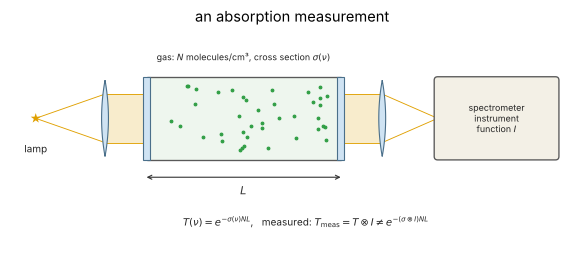

In [2]:
fig, ax = plt.subplots(figsize=(11, 3.6))
sketch.absorption_layout(ax, "cell", title="an absorption measurement")
plt.show()

In [3]:
nu = np.arange(1.0, 20001.0, 1.0)         # cm^-1, an odd/even grid for Maclaurin
nu0, f_osc, gam, eps_inf = 2000.0, 0.05, 40.0, 2.25
n_c = spc.lorentz_index(nu, nu0, f_osc, gam, eps_inf)
n_kk = np.sqrt(eps_inf) + spc.kramers_kronig(nu, n_c.imag)
n_fdtd = np.sqrt(eps_inf + Lorentz(f_osc, nu0, gam).chi(nu))

win = (nu > 1500) & (nu < 2500)
print("max |n - n_KK|      = {:.1e}  (in 1500..2500 cm^-1)".format(np.max(np.abs(n_c.real - n_kk)[win])))
print("max |n - n_FDTD|    = {:.1e}".format(np.max(np.abs(n_c - n_fdtd))))
print("peak kappa          = {:.4f} at {:.0f} cm^-1".format(n_c.imag.max(), nu[np.argmax(n_c.imag)]))
print("n range near nu0    = {:.4f} .. {:.4f}".format(n_c.real[win].min(), n_c.real[win].max()))
alpha = 4*np.pi*nu*n_c.imag
print("peak alpha          = {:.0f} cm^-1  (1/e depth {:.1f} um)".format(alpha.max(), 1e4/alpha.max()))
# group index n_g = n + nu dn/dnu
n_g = n_c.real + nu*np.gradient(n_c.real, nu)
print("group index range   = {:.2f} .. {:.2f}".format(n_g[win].min(), n_g[win].max()))
print("FWHM of kappa       = {:.1f} cm^-1 (gamma {:.0f})".format(spc.fwhm(nu[win], n_c.imag[win]), gam))

max |n - n_KK|      = 7.2e-08  (in 1500..2500 cm^-1)
max |n - n_FDTD|    = 0.0e+00
peak kappa          = 0.7789 at 2005 cm^-1
n range near nu0    = 1.1070 .. 1.9083
peak alpha          = 19625 cm^-1  (1/e depth 0.5 um)
group index range   = -67.81 .. 11.67
FWHM of kappa       = 44.1 cm^-1 (gamma 40)


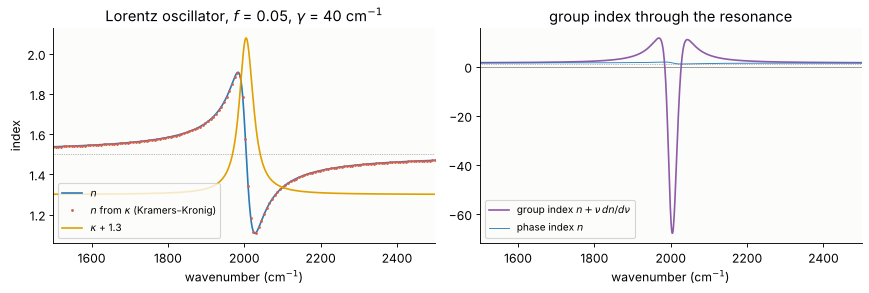

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(nu, n_c.real, color=BLUE, label="$n$")
ax[0].plot(nu[::7], n_kk[::7], ".", color=RED, ms=3, label="$n$ from $\\kappa$ (Kramers–Kronig)")
ax[0].plot(nu, n_c.imag + 1.3, color=ORANGE, label="$\\kappa$ + 1.3")
ax[0].axhline(np.sqrt(eps_inf), color=GREY, lw=0.6, ls=":")
ax[0].set_xlim(1500, 2500); ax[0].set_xlabel("wavenumber (cm$^{-1}$)"); ax[0].set_ylabel("index")
ax[0].legend(fontsize=9, loc="lower left"); ax[0].set_title("Lorentz oscillator, $f$ = 0.05, $\\gamma$ = 40 cm$^{-1}$")
ax[1].plot(nu, n_g, color=PURPLE, label="group index $n + \\nu\\,dn/d\\nu$")
ax[1].plot(nu, n_c.real, color=BLUE, lw=0.8, label="phase index $n$")
ax[1].axhline(1, color=GREY, lw=0.6, ls=":"); ax[1].axhline(0, color=GREY, lw=0.6)
ax[1].set_xlim(1500, 2500); ax[1].set_xlabel("wavenumber (cm$^{-1}$)")
ax[1].legend(fontsize=9); ax[1].set_title("group index through the resonance")
plt.tight_layout(); plt.show()

The Kramers–Kronig integral of $\kappa$ alone gives back $n$ to
$7\times10^{-8}$, and the FDTD susceptibility (with the frequency in
cm⁻¹ instead of rad/s, which does not matter for the shape) is identical
to the last bit: the time convention $e^{-i\omega t}$, with
$\kappa > 0$ for absorption, is the same in both parts of the library.

This oscillator is strong ($f$ = 0.05 against a background of
$\varepsilon_\infty$ = 2.25): $\kappa$ peaks at 0.78, an absorption
coefficient of 2 × 10⁴ cm⁻¹, so the light is gone within half a micron,
as in a phonon band of a solid or a dye film. The real index swings from
1.91 just below the resonance to 1.11 just above it, and the absorption
FWHM of 44 cm⁻¹ is a little wider than $\gamma$ = 40 cm⁻¹ because the
line is strong enough to shift and distort itself (for a weak oscillator
the two agree).

The **group index** $n + \nu\,dn/d\nu$ dips to −68 in the absorption
band: a pulse peak would leave the medium before it entered. Nothing
travels faster than light, however: the "pulse" that comes out is
reshaped by the strong absorption, and the front of any signal still
moves at $c$. Away from the band, on either side, the group index is
larger than the phase index (11.7 at the maximum), which is the slow
light of resonant media. For gases the same curves hold with an
oscillator strength smaller by orders of magnitude; they are what makes
the refractive index of air rise towards the ultraviolet (notebook 101, atmospheric dispersion corrector)
and the dispersion of glasses follow Sellmeier's formula, which is a sum
of Lorentz oscillators with the damping left out.

## 2. Broadening: natural, Doppler and pressure

A line is never infinitely narrow. Three mechanisms set its width:

* **Natural width.** An excited state that decays with the lifetime
  $\tau$ radiates a damped wave, whose spectrum is a Lorentzian of FWHM
  $1/(2\pi\tau)$. For the sodium D2 line, $\tau$ = 16.2 ns.
* **Doppler broadening.** Atoms moving along the line of sight at the
  speed $v$ emit and absorb at $\nu(1 + v/c)$. The Maxwell distribution
  makes the line a Gaussian of FWHM $\nu_0\sqrt{8kT\ln 2/(mc^2)}$
  (`doppler_fwhm()`). A bulk motion shifts the whole line, which is how
  the radial velocities of stars are measured with the echelle of
  notebook 100 (echelle spectrograph).
* **Pressure (collisional) broadening.** Collisions interrupt the phase
  of the oscillating dipole, which again gives a Lorentzian, of width
  proportional to the pressure. For CO₂ lines in air the half width is
  about 0.07 cm⁻¹ per atmosphere.

Doppler and Lorentz broadening act together, and the line shape is their
convolution, the **Voigt profile** (`voigt()`, the real part of the
Faddeeva function). Its FWHM is given to 0.02 % by the Olivero and
Longbothum formula (`voigt_fwhm()`).

In [5]:
# natural width of Na D2
tau_Na = 16.2e-9
nu_Na = C_LIGHT/589.158e-9
nat = 1/(2*np.pi*tau_Na)
dop_Na = spc.doppler_fwhm(nu_Na, 500.0, 22.99)
print("Na D2 natural FWHM      = {:.2f} MHz".format(nat/1e6))
print("Na D2 Doppler FWHM 500 K = {:.2f} GHz  (x{:.0f})".format(dop_Na/1e9, dop_Na/nat))

# CO2 at 2349 cm^-1
nu_co2 = 2349.0
gamma_air = 0.07              # cm^-1/atm HWHM
dop_co2 = spc.doppler_fwhm(nu_co2, 296.0, 44.0)
p_cross = dop_co2/(2*gamma_air)
print("CO2 Doppler FWHM 296 K  = {:.4f} cm^-1 = {:.0f} MHz".format(dop_co2, dop_co2*C_LIGHT*100/1e6))
print("Lorentz = Doppler at p  = {:.3f} atm".format(p_cross))
print("Radial velocity 1 km/s shift = {:.4f} cm^-1  ({:.2f} x Doppler FWHM)".format(
    nu_co2*1e3/C_LIGHT, nu_co2*1e3/C_LIGHT/dop_co2))

# check Olivero-Longbothum against the numerical width
x = np.linspace(-2, 2, 400001)
errs = []
for fl in np.geomspace(1e-4, 1, 9):
    v = spc.voigt(x, 0, dop_co2, fl)
    errs.append(spc.fwhm(x, v)/spc.voigt_fwhm(dop_co2, fl) - 1)
print("Voigt FWHM formula error: max {:.1e}".format(np.max(np.abs(errs))))

Na D2 natural FWHM      = 9.82 MHz
Na D2 Doppler FWHM 500 K = 1.70 GHz  (x173)
CO2 Doppler FWHM 296 K  = 0.0044 cm^-1 = 131 MHz
Lorentz = Doppler at p  = 0.031 atm
Radial velocity 1 km/s shift = 0.0078 cm^-1  (1.80 x Doppler FWHM)


Voigt FWHM formula error: max 2.3e-04


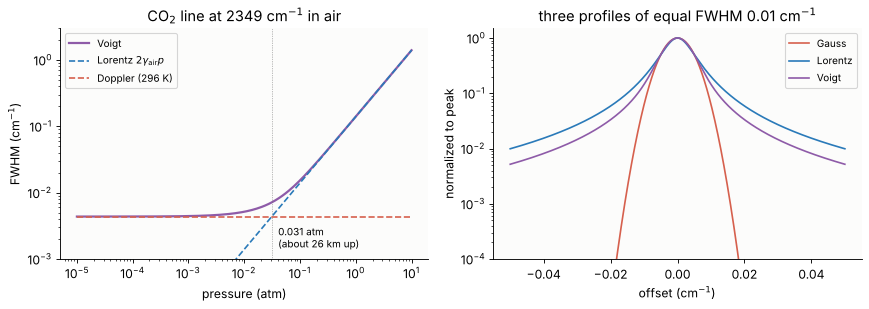

Voigt FWHM check: 0.01000
at 0.02: Gauss 1.5e-05, Lorentz 5.9e-02, Voigt 3.3e-02
at 0.04: Gauss 5.4e-20, Lorentz 1.5e-02, Voigt 8.1e-03


In [6]:
p = np.geomspace(1e-5, 10, 200)
fl = 2*gamma_air*p
fv = spc.voigt_fwhm(dop_co2, fl)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].loglog(p, fv, color=PURPLE, lw=2, label="Voigt")
ax[0].loglog(p, fl, color=BLUE, ls="--", label="Lorentz $2\\gamma_\\mathrm{air}p$")
ax[0].loglog(p, np.full_like(p, dop_co2), color=RED, ls="--", label="Doppler (296 K)")
ax[0].axvline(p_cross, color=GREY, lw=0.6, ls=":")
ax[0].set_xlabel("pressure (atm)"); ax[0].set_ylabel("FWHM (cm$^{-1}$)")
ax[0].set_ylim(1e-3, 3); ax[0].legend(fontsize=9)
ax[0].set_title("CO$_2$ line at 2349 cm$^{-1}$ in air")
ax[0].text(p_cross*1.3, 1.5e-3, "{:.3f} atm\n(about 26 km up)".format(p_cross), fontsize=9)

d = np.linspace(-0.05, 0.05, 4001)
w = 0.01
g = spc.gaussian(d, 0, w); l = spc.lorentzian(d, 0, w)
fg_eq = 0.0062
v = spc.voigt(d, 0, fg_eq, w*0.6)
v_w = spc.voigt_fwhm(fg_eq, w*0.6)
v = spc.voigt(d, 0, fg_eq*w/v_w, w*0.6*w/v_w)
ax[1].semilogy(d, g/g.max(), color=RED, label="Gauss")
ax[1].semilogy(d, l/l.max(), color=BLUE, label="Lorentz")
ax[1].semilogy(d, v/v.max(), color=PURPLE, label="Voigt")
ax[1].set_ylim(1e-4, 1.5); ax[1].set_xlabel("offset (cm$^{-1}$)")
ax[1].set_ylabel("normalized to peak"); ax[1].legend(fontsize=9)
ax[1].set_title("three profiles of equal FWHM 0.01 cm$^{-1}$")
plt.tight_layout(); plt.show()
print("Voigt FWHM check: {:.5f}".format(spc.fwhm(d, v)))
for off in (0.02, 0.04):
    i = np.argmin(np.abs(d - off))
    print("at {:.2f}: Gauss {:.1e}, Lorentz {:.1e}, Voigt {:.1e}".format(off, g[i]/g.max(), l[i]/l.max(), v[i]/v.max()))

**Which width wins.** The natural width of Na D2, 9.8 MHz, is 173 times
smaller than the Doppler width of a 500 K sodium lamp, 1.7 GHz. That is the
rule for atoms in the visible: the natural width is seen only in atomic
beams or with Doppler-free laser methods. The CO₂ line at 4.3 µm has a
Doppler FWHM of only 0.0044 cm⁻¹ (131 MHz), because the Doppler width
scales with the frequency and the molecule is heavy. Pressure broadening
of 0.14 cm⁻¹ FWHM per atmosphere overtakes it at 0.031 atm, which in the
atmosphere is about 26 km up. Below that altitude infrared lines are
Lorentzian, above it Gaussian, and the remote sensing of the temperature
and composition of the atmosphere from satellites uses this change of
shape with height. The Olivero–Longbothum formula agrees with the
numerical width of the Voigt profile to 2 × 10⁻⁴ over the whole range.

A bulk motion of 1 km/s shifts the CO₂ line by 0.0078 cm⁻¹, about twice
its Doppler width; the stellar radial velocities of tens of km/s in
notebook 100 (echelle spectrograph) are many line widths.

**Wings.** For the same FWHM the profiles differ enormously away from the
centre. Two FWHM out, the Gaussian has fallen to 10⁻⁵ of its peak, the
Lorentzian only to 6 %, and the Voigt sits in between with 3 %.
At four FWHM the Gaussian is at 10⁻²⁰, but the Lorentzian is still at
1.5 %. Far out, the Voigt profile always becomes Lorentzian. These wings
decide how saturated lines grow (section 4) and why the many weak far
wings of water lines make up a continuum in the infrared.

## 3. A model CO₂ band

The strongest infrared band of CO₂ is the asymmetric stretch ν₃ at
2349 cm⁻¹ (4.26 µm), which is why non-dispersive infrared CO₂ sensors and
the CO₂ channels of weather satellites look there. Its line positions
follow, to a fraction of a line width, from a vibrating rigid rotor with
the rotational constants $B''$ = 0.39022 cm⁻¹ (ground state) and
$B'$ = 0.38714 cm⁻¹ (upper state):

$$ R(J):\ \nu_0 + B'(J+1)(J+2) - B''J(J+1), \qquad
   P(J):\ \nu_0 + B'(J-1)J - B''J(J+1). $$

The line strengths follow the Boltzmann population of the lower level
times the Hönl–London factor. The two oxygen-16 nuclei are identical
bosons with spin 0, so only even $J$ exist in the ground state and every
second line is missing: the lines are $4B$ ≈ 1.56 cm⁻¹ apart, not $2B$.
`linear_molecule_band()` returns this line list. The band strength,
9.6 × 10⁻¹⁷ cm/molecule, is the sum of the line strengths of the main
isotopologue. This is all a model needs; real line lists (HITRAN) add
hot bands, isotopologues, centrifugal distortion and individual
broadening coefficients, which are corrections of a few percent here.

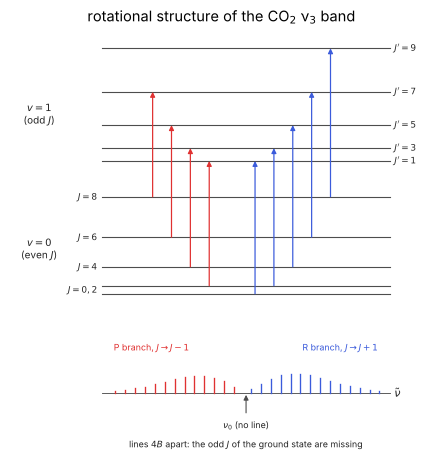

In [7]:
fig, ax = plt.subplots(figsize=(7, 7))
sketch.absorption_layout(ax, "levels", title="rotational structure of the CO$_2$ ν$_3$ band")
plt.show()

In [8]:
NU0, B_LO, B_UP = 2349.14, 0.39022, 0.38714
S_BAND = 9.6e-17                      # cm/molecule
N_AIR = 2.479e19                      # molecules/cm^3 at 296 K, 1 atm
X_CO2 = 420e-6
FD_296 = spc.doppler_fwhm(NU0, 296.0, 44.0)


def co2_band(T=296.0, J_max=100):
    pos, S, lab = spc.linear_molecule_band(NU0, B_LO, B_UP, T, J_max=J_max, even_only=True,
                                           strength=S_BAND)
    return pos, S, lab


def cross_section(nu, T=296.0, p=1.0):
    pos, S, _ = co2_band(T)
    fd = spc.doppler_fwhm(NU0, T, 44.0)
    fl = 2*gamma_air*p*(296.0/T)**0.75
    keep = S > 1e-6*S.max()
    return spc.line_list_spectrum(nu, pos[keep], S[keep], fd, fl)


pos, S, lab = co2_band(296.0)
i_max = np.argmax(S)
hc_k = 1.4387769
J_pk = np.sqrt(296*0.6950348/(2*B_LO)) - 0.5
print("{} lines; strongest {} at {:.3f} cm^-1, S = {:.2e} cm/molecule".format(len(S), lab[i_max], pos[i_max], S[i_max]))
print("expected J of the branch maximum: sqrt(kT/2hcB) - 1/2 = {:.1f}".format(J_pk))
r = [p_ for p_, l_ in zip(pos, lab) if l_.startswith("R")]
print("R line spacing near origin: {:.3f} cm^-1".format(r[1] - r[0]))
gap = min(pos[np.char.startswith(lab, "R")]) - max(pos[np.char.startswith(lab, "P")])
print("gap at the band origin: {:.3f} cm^-1".format(gap))
pos1000, S1000, lab1000 = co2_band(1000.0)
print("1000 K strongest {}".format(lab1000[np.argmax(S1000)]))

101 lines; strongest R(16) at 2361.465 cm^-1, S = 3.69e-18 cm/molecule
expected J of the branch maximum: sqrt(kT/2hcB) - 1/2 = 15.7
R line spacing near origin: 1.530 cm^-1
gap at the band origin: 2.341 cm^-1
1000 K strongest R(30)


peak cross section 296 K = 1.69e-17 cm^2


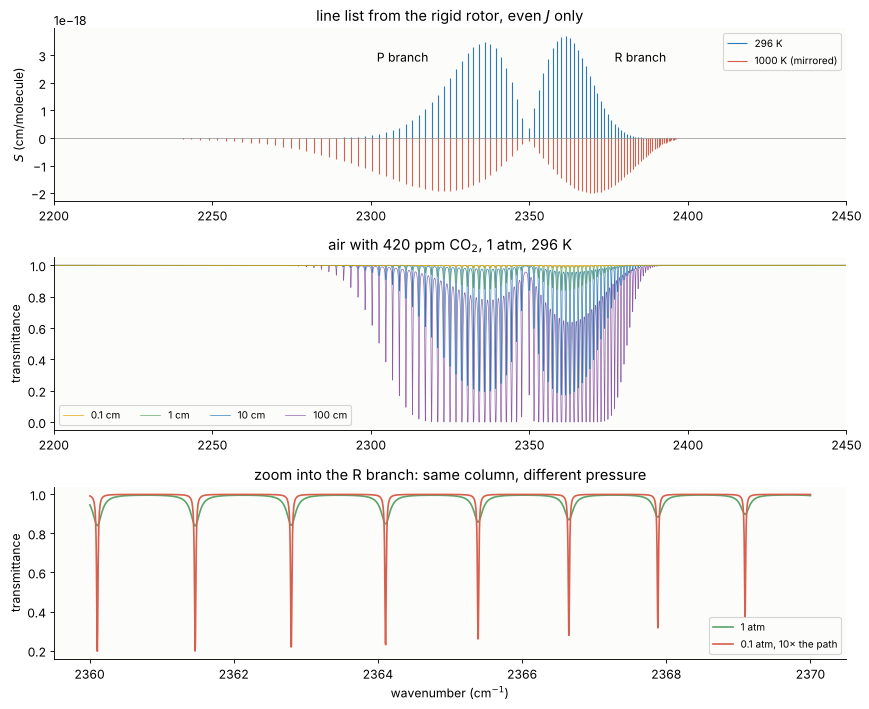

same column 1.04e16: W(1 atm) 0.2472, W(0.1 atm) 0.1928 cm^-1 over 2360..2370
path    0.1 cm: column 1.04e+15 /cm^2, min T 0.983, band W 0.1 cm^-1
path    1.0 cm: column 1.04e+16 /cm^2, min T 0.839, band W 1.0 cm^-1
path   10.0 cm: column 1.04e+17 /cm^2, min T 0.172, band W 7.7 cm^-1
path  100.0 cm: column 1.04e+18 /cm^2, min T 0.000, band W 31.7 cm^-1


In [9]:
nu_b = np.arange(2200.0, 2450.0, 0.004)
sig296 = cross_section(nu_b, 296.0)
sig1000 = cross_section(nu_b, 1000.0)
print("peak cross section 296 K = {:.2e} cm^2".format(sig296.max()))
paths = [0.1, 1.0, 10.0, 100.0]                            # cm of air at 420 ppm
fig, ax = plt.subplots(3, 1, figsize=(11, 9))
ax[0].vlines(pos, 0, S, color=BLUE, lw=1, label="296 K")
ax[0].vlines(pos1000, 0, -S1000, color=RED, lw=1, label="1000 K (mirrored)")
ax[0].axhline(0, color=GREY, lw=0.5)
ax[0].set_xlim(2200, 2450); ax[0].set_ylabel("$S$ (cm/molecule)"); ax[0].legend(fontsize=9)
ax[0].text(2310, S.max()*0.75, "P branch", ha="center"); ax[0].text(2385, S.max()*0.75, "R branch", ha="center")
ax[0].set_title("line list from the rigid rotor, even $J$ only")
for L, c in list(zip(paths, (ORANGE, GREEN, BLUE, PURPLE)))[::-1]:
    col = N_AIR*X_CO2*L
    ax[1].plot(nu_b, np.exp(-sig296*col), color=c, lw=0.6, label="{:g} cm".format(L))
ax[1].set_xlim(2200, 2450); ax[1].set_ylabel("transmittance")
h_, l_ = ax[1].get_legend_handles_labels()
ax[1].legend(h_[::-1], l_[::-1], fontsize=9, ncol=4, loc="lower left"); ax[1].set_title("air with 420 ppm CO$_2$, 1 atm, 296 K")
z = (nu_b > 2360) & (nu_b < 2370)
ax[2].plot(nu_b[z], np.exp(-sig296[z]*N_AIR*X_CO2*1.0), color=GREEN, label="1 atm")
T_low = np.exp(-cross_section(nu_b[z], 296, 0.1)*0.1*N_AIR*X_CO2*10.0)
ax[2].plot(nu_b[z], T_low, color=RED,
           label="0.1 atm, 10× the path")
ax[2].set_xlabel("wavenumber (cm$^{-1}$)"); ax[2].set_ylabel("transmittance")
ax[2].legend(fontsize=9); ax[2].set_title("zoom into the R branch: same column, different pressure")
plt.tight_layout(); plt.show()
print("same column 1.04e16: W(1 atm) {:.4f}, W(0.1 atm) {:.4f} cm^-1 over 2360..2370".format(
    spc.equivalent_width(nu_b[z], np.exp(-sig296[z]*N_AIR*X_CO2*1.0)), spc.equivalent_width(nu_b[z], T_low)))
for L in paths:
    col = N_AIR*X_CO2*L
    T = np.exp(-sig296*col)
    print("path {:6.1f} cm: column {:.2e} /cm^2, min T {:.3f}, band W {:.1f} cm^-1".format(
        L, col, T.min(), spc.equivalent_width(nu_b, T)))

The model reproduces the familiar shape of the 4.3 µm band. The two
branches are separated by a gap at the band origin (there is no Q branch in a
parallel band of a linear molecule), the even-$J$ lines are 1.53 cm⁻¹ apart
near the origin and closer together towards the band head of the R branch,
because $B' < B''$. The strongest line is R(16) at 2361.47 cm⁻¹ with
3.7 × 10⁻¹⁸ cm/molecule, as expected from the maximum of the population
$\sqrt{kT/2hcB} - 1/2 = 15.7$; in HITRAN, R(16) of the main
isotopologue is indeed the strongest line of the band, at about
3.5 × 10⁻¹⁸.
At 1000 K, the population spreads to higher $J$, the strongest line is R(30)
and the band is almost twice as wide (rms width 33 against 18 cm⁻¹): hot CO₂ in flames and engine exhausts is
recognised by its wide wings. (The model keeps the band strength fixed
and leaves out the hot bands, which in reality add many more lines at
1000 K.)

At 1 atm the peak cross section is 1.7 × 10⁻¹⁷ cm², so the 420 ppm in air
already absorb 16 % at the strongest line over 1 cm, 83 % over 10 cm, and
the centre of the band is black over 1 m. The equivalent width of the band
grows from 0.1 to 1.0, 7.7 and 31.7 cm⁻¹ for 0.1, 1, 10 and 100 cm: linear
at first, then much more slowly.

The bottom panel compares the same column of CO₂ at 1 atm (1 cm) and at
0.1 atm (10 cm). The low pressure lines are narrower and therefore deeper
for the same number of molecules, and in fact already partly saturated:
their equivalent width over the plotted 10 cm⁻¹ is 0.193 against
0.247 cm⁻¹ at 1 atm. Concentrations can only be read from lines if the
pressure is known.

## 4. The curve of growth

The **equivalent width** $W = \int (1 - T)\,d\nu$ is the width of a
rectangular, totally black line that takes away as much light as the
real one. For a single line of strength $S$ and a column $N$ of
absorbers, with the optical depth $\tau(\nu) = SN\phi(\nu)$ and the peak
$\tau_0$, $W$ grows in three stages:

* **weak line** ($\tau_0 \ll 1$): $W = SN$, independent of the shape;
* **saturated core** (Doppler): the centre is black and only the
  Gaussian edges move out, $W \approx 2b\sqrt{\ln\tau_0}$ with
  $b$ = FWHM/$(2\sqrt{\ln 2})$, nearly flat;
* **damping wings** (Lorentz): the $1/\Delta\nu^2$ wings take over,
  $W = 2\sqrt{SN\gamma_{1/2}}$ with the half width $\gamma_{1/2}$.

Astronomers read abundances in stellar atmospheres off this curve; in
the laboratory it decides whether a concentration can be read off the
depth of a line, its area, or neither.

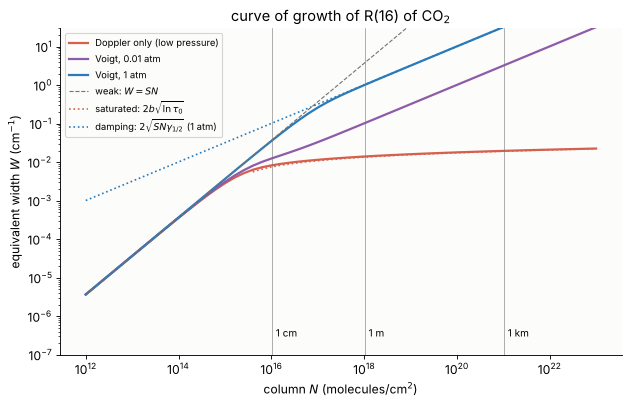

N = 1e+15: W/SN Doppler 0.771, 1 atm 0.996; tau0 (1 atm) 0.017
N = 1e+17: W/SN Doppler 0.031, 1 atm 0.709; tau0 (1 atm) 1.7
N = 1e+19: W/SN Doppler 0.000, 1 atm 0.087; tau0 (1 atm) 1.7e+02
N = 1e+21: W/SN Doppler 0.000, 1 atm 0.009; tau0 (1 atm) 1.7e+04
1 atm at 1e22: W 101.364, damping formula 101.693
Doppler at 1e20: W 0.0180, sqrt(ln) formula 0.0176


In [10]:
S_line = S[i_max]
cols = np.geomspace(1e12, 1e23, 56)
u = np.sinh(np.linspace(-np.arcsinh(5e7), np.arcsinh(5e7), 200001))*1e-4   # cm^-1, fine at centre, to +-5000
cases = [("Doppler only (low pressure)", FD_296, 0.0, RED),
         ("Voigt, 0.01 atm", FD_296, 2*gamma_air*0.01, PURPLE),
         ("Voigt, 1 atm", FD_296, 2*gamma_air*1.0, BLUE)]
W = {}
for name, fd, fl_, c in cases:
    phi = spc.voigt(u, 0, fd, fl_) if fl_ > 0 else spc.gaussian(u, 0, fd)
    W[name] = np.array([spc.equivalent_width(u, np.exp(-S_line*N*phi)) for N in cols])

fig, ax = plt.subplots(figsize=(8, 5.2))
for name, fd, fl_, c in cases:
    ax.loglog(cols, W[name], color=c, lw=2, label=name)
ax.loglog(cols, S_line*cols, color=GREY, ls="--", lw=1, label="weak: $W = SN$")
b = FD_296/(2*np.sqrt(np.log(2)))
tau0_D = S_line*cols*spc.gaussian(0, 0, FD_296)
ax.loglog(cols[tau0_D > 3], 2*b*np.sqrt(np.log(tau0_D[tau0_D > 3])), color=RED, ls=":", lw=1.5,
          label="saturated: $2b\\sqrt{\\ln\\tau_0}$")
ax.loglog(cols, 2*np.sqrt(S_line*cols*gamma_air), color=BLUE, ls=":", lw=1.5,
          label="damping: $2\\sqrt{SN\\gamma_{1/2}}$ (1 atm)")
for L in (1.0, 100.0, 1e5):
    ax.axvline(N_AIR*X_CO2*L, color=GREY, lw=0.5)
ax.text(N_AIR*X_CO2*1.0*1.2, 3e-7, "1 cm", fontsize=9)
ax.text(N_AIR*X_CO2*100*1.2, 3e-7, "1 m", fontsize=9)
ax.text(N_AIR*X_CO2*1e5*1.2, 3e-7, "1 km", fontsize=9)
ax.set_ylim(1e-7, 30); ax.set_xlabel("column $N$ (molecules/cm$^2$)")
ax.set_ylabel("equivalent width $W$ (cm$^{-1}$)")
ax.set_title("curve of growth of {} of CO$_2$".format(lab[i_max]))
ax.legend(fontsize=8.5, loc="upper left")
plt.tight_layout(); plt.show()

for N in (1e15, 1e17, 1e19, 1e21):
    k = np.argmin(np.abs(cols - N))
    print("N = {:.0e}: W/SN Doppler {:.3f}, 1 atm {:.3f}; tau0 (1 atm) {:.2g}".format(
        cols[k], W[cases[0][0]][k]/(S_line*cols[k]), W[cases[2][0]][k]/(S_line*cols[k]),
        S_line*cols[k]*spc.voigt(0, 0, FD_296, 2*gamma_air)))
k = np.argmin(np.abs(cols - 1e22))
print("1 atm at 1e22: W {:.3f}, damping formula {:.3f}".format(W[cases[2][0]][k], 2*np.sqrt(S_line*cols[k]*gamma_air)))
k = np.argmin(np.abs(cols - 1e20))
print("Doppler at 1e20: W {:.4f}, sqrt(ln) formula {:.4f}".format(W[cases[0][0]][k],
      2*b*np.sqrt(np.log(S_line*cols[k]*spc.gaussian(0, 0, FD_296)))))

The three curves start together on the line $W = SN$: as long as the line
is optically thin, its area counts the molecules whatever its shape. The
Doppler line (FWHM 0.0044 cm⁻¹) leaves the straight line first, at
$N \approx 10^{14}$ cm⁻² (W/SN = 0.77 at 10¹⁵ cm⁻²), and then enters the
flat part where the equivalent width barely moves: 0.018 cm⁻¹ at
10²⁰ cm⁻² against 0.0176 cm⁻¹ from $2b\sqrt{\ln\tau_0}$. A hundred times
more absorber adds only a few percent of $W$. A concentration can hardly
be measured in this part of the curve.

At 1 atm the line is 30 times wider and stays linear 30 times longer:
W/SN is still 0.996 at 10¹⁵, 0.71 at 10¹⁷ (where the peak optical depth
reaches 1.7). Beyond it the Lorentzian wings take over, and $W$ follows
the square root law; at 10²² cm⁻² the computed 101.4 cm⁻¹ and the
asymptote $2\sqrt{SN\gamma_{1/2}}$ = 101.7 cm⁻¹ agree to 0.3 %. (For a
real band such a single line would long have merged with its neighbours;
the band of section 3 is black at 1 m.) At 0.01 atm the line runs
along the Doppler plateau before the Lorentz wings, a hundred times
weaker than at 1 atm, take over at large columns.

Typical paths in air with 420 ppm CO₂ are marked: R(16) at 1 atm is
linear for paths up to about 1 cm and on the square root branch for
anything longer than a metre. Gas sensors with long paths, and the
atmosphere seen from space, live on the square root branch.

## 5. What the instrument makes of it

Every spectrometer of notebooks 110 (grating and prism spectrometers), 111 (Fourier transform spectroscopy) and 113 (Fabry–Perot and filters) measures the true spectrum
convolved with its instrument function: the trapezoid of the slits of a
grating spectrometer, the sinc or apodized line shape of an FTS
(notebook 111, Fourier transform spectroscopy), the Airy peak of a Fabry–Perot. For an absorption
measurement with a flat source the measured transmittance is

$$ T_\mathrm{meas}(\nu) = \int T(\nu')\,I(\nu - \nu')\,d\nu', \qquad
   T = e^{-\sigma(\nu) N}. $$

Taking $-\log T_\mathrm{meas}$ is *not* $\sigma N$ convolved with $I$:
the logarithm and the convolution do not commute. Unresolved lines
therefore violate Beer–Lambert; the apparent absorbance grows more
slowly than the concentration. Below, 1 m of air with 420 ppm CO₂ is
measured with a grating spectrometer at a triangle slit function of
1 cm⁻¹ FWHM, and with an FTS at maximum path differences of 0.5 and
5 cm, boxcar and Norton–Beer medium apodized.

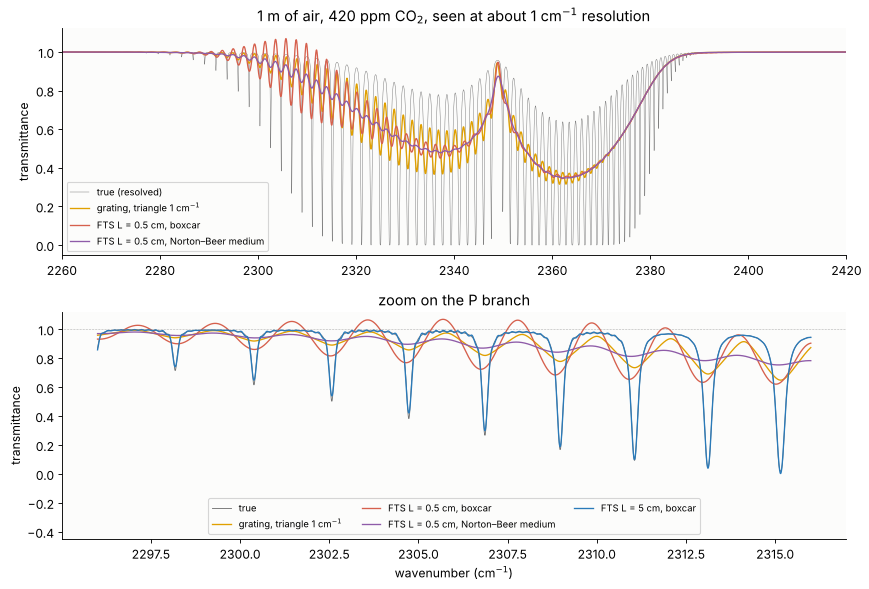

grating, triangle 1 cm                   W = 31.681 (true 31.681), max T = 1.000
FTS L = 0.5 cm, boxcar                   W = 31.681 (true 31.681), max T = 1.069
FTS L = 0.5 cm, Norton–Beer medium       W = 31.681 (true 31.681), max T = 1.000
FTS L = 5 cm, boxcar                     W = 31.681 (true 31.681), max T = 1.000


In [11]:
x_win = 15.0       # half width of the kernel support (cm^-1)


def ils_kernel(L, kind):
    def k(dx):
        out = np.zeros_like(dx)
        m = np.abs(dx) < x_win
        out[m] = spc.instrument_line_shape(dx[m], L, kind, n=801)
        return out/(out.sum()*(dx[1] - dx[0]))      # unit area after truncation

    return k


col_1m = N_AIR*X_CO2*100.0
T_true = np.exp(-sig296*col_1m)
inst = [("grating, triangle 1 cm$^{-1}$", lambda dx: spc.slit_function(dx, 1.0, 1.0), ORANGE),
        ("FTS L = 0.5 cm, boxcar", ils_kernel(0.5, "boxcar"), RED),
        ("FTS L = 0.5 cm, Norton–Beer medium", ils_kernel(0.5, "norton_beer_medium"), PURPLE),
        ("FTS L = 5 cm, boxcar", ils_kernel(5.0, "boxcar"), BLUE)]
meas = {}
for name, k, c in inst:
    meas[name] = spc.convolve(nu_b, T_true, k)

fig, ax = plt.subplots(2, 1, figsize=(11, 7.5))
ax[0].plot(nu_b, T_true, color=GREY, lw=0.4, label="true (resolved)")
for name, k, c in inst[:3]:
    ax[0].plot(nu_b, meas[name], color=c, lw=1.2, label=name)
ax[0].set_xlim(2260, 2420); ax[0].legend(fontsize=8.5, loc="lower left")
ax[0].set_ylabel("transmittance"); ax[0].set_title("1 m of air, 420 ppm CO$_2$, seen at about 1 cm$^{-1}$ resolution")
z = (nu_b > 2296) & (nu_b < 2316)
ax[1].plot(nu_b[z], T_true[z], color=GREY, lw=0.8, label="true")
for name, k, c in inst:
    ax[1].plot(nu_b[z], meas[name][z], color=c, lw=1.2, label=name)
ax[1].axhline(1, color=GREY, lw=0.5, ls=":")
ax[1].set_xlabel("wavenumber (cm$^{-1}$)"); ax[1].set_ylabel("transmittance")
ax[1].set_ylim(-0.45, 1.12); ax[1].legend(fontsize=8.5, loc="lower center", ncol=3); ax[1].set_title("zoom on the P branch")
plt.tight_layout(); plt.show()
W_true = spc.equivalent_width(nu_b, T_true)
for name, k, c in inst:
    print("{:40s} W = {:.3f} (true {:.3f}), max T = {:.3f}".format(name.replace("$^{-1}$", ""), spc.equivalent_width(nu_b, meas[name]), W_true, meas[name].max()))

At 1 cm⁻¹ resolution the band is a smooth envelope with a ripple at the
line spacing. None of the black line centres survives: the deepest point
of the measured R branch is at T = 0.31, although every line centre
there is black.

The **boxcar** FTS of the same nominal resolution rings: its sinc line
shape has negative side lobes of 22 %, and where the true spectrum has
narrow, deep lines next to clear gaps the convolution overshoots to a
transmittance of 1.069. A transmittance above one is the most common
sign of an unapodized FTS spectrum of a gas. Norton–Beer medium
apodization removes the ringing (maximum 1.000) at the cost of a wider
line shape. With $L$ = 5 cm the boxcar FTS has a resolution of
0.12 cm⁻¹, comparable to the line width at 1 atm, and follows the true
spectrum closely.

All four measured spectra have the same equivalent width as the true
one, 31.681 cm⁻¹, to all printed digits. This is not a coincidence:
$\int(1 - T\otimes I)\,d\nu = \int(1 - T)\,d\nu$ for any instrument
function of unit area. Ringing and smoothing move absorption around,
but they cannot create or destroy it.

**Beer–Lambert and its failure.** Take the absorbance of one line,
R(16) here, at its peak, as a concentration measurement: below, the
column grows from a trace to percent levels and the line is measured with
triangle slit functions of growing width. A fully resolving
instrument follows the straight line $A = \sigma_0 N/\ln 10$ until the
line goes black; every coarser one bends over much earlier. The
band equivalent width instead follows the same curve for every
instrument, so a calibration on $W$ transfers between instruments,
while a calibration on peak absorbance holds only for the instrument it
was made with.

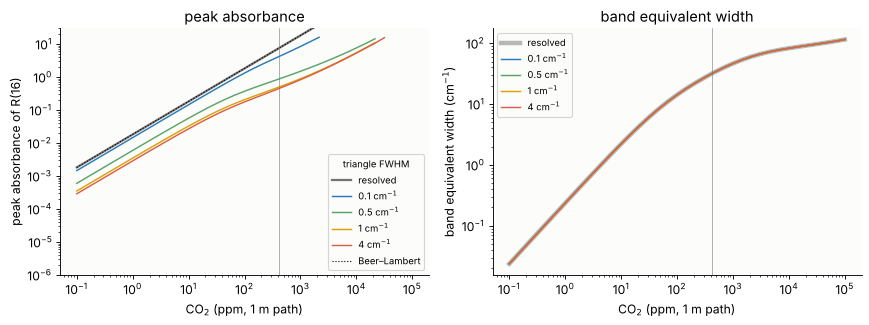

ppm grid points used: 1, 420
res  0.0: A at 1 ppm 1.82e-02, at 420 ppm 7.647; A/A_lin at 420 ppm 1.000; W spread 0.0e+00
res  0.1: A at 1 ppm 1.46e-02, at 420 ppm 4.237; A/A_lin at 420 ppm 0.554; W spread 1.0e-08
res  0.5: A at 1 ppm 5.96e-03, at 420 ppm 0.881; A/A_lin at 420 ppm 0.115; W spread 1.4e-07
res  1.0: A at 1 ppm 3.49e-03, at 420 ppm 0.502; A/A_lin at 420 ppm 0.066; W spread 5.4e-07
res  4.0: A at 1 ppm 2.87e-03, at 420 ppm 0.454; A/A_lin at 420 ppm 0.059; W spread 8.8e-06


In [12]:
i_r16 = np.where(lab == "R(16)")[0][0]
nu_r16 = pos[i_r16]
zl = (nu_b > nu_r16 - 0.7) & (nu_b < nu_r16 + 0.7)
i_c = np.argmin(np.abs(nu_b - nu_r16))
ppm = np.sort(np.concatenate([np.geomspace(0.1, 1e5, 37), [1.0, 420.0]]))   # ppm over 1 m
resolutions = [0.0, 0.1, 0.5, 1.0, 4.0]
colors = [GREY, BLUE, GREEN, ORANGE, RED]
A_peak = {r_: [] for r_ in resolutions}
W_band = {r_: [] for r_ in resolutions}
for xppm in ppm:
    T_ = np.exp(-sig296*N_AIR*xppm*1e-6*100.0)
    for r_ in resolutions:
        Tm = T_ if r_ == 0 else spc.convolve(nu_b, T_, lambda dx, w=r_: spc.slit_function(dx, w, w))
        A_peak[r_].append(spc.absorbance(Tm[zl].min()))
        W_band[r_].append(spc.equivalent_width(nu_b, Tm))

fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
for r_, c in zip(resolutions, colors):
    ax[0].loglog(ppm, A_peak[r_], color=c, lw=2 if r_ == 0 else 1.3,
                 label="resolved" if r_ == 0 else "{:g} cm$^{{-1}}$".format(r_))
    ax[1].loglog(ppm, W_band[r_], color=c, lw=4 if r_ == 0 else 1.3, alpha=0.5 if r_ == 0 else 1,
                 label="resolved" if r_ == 0 else "{:g} cm$^{{-1}}$".format(r_))
A_lin = sig296[i_c]*N_AIR*ppm*1e-6*100.0/np.log(10)
ax[0].loglog(ppm, A_lin, color="k", ls=":", lw=1, label="Beer–Lambert")
ax[0].set_ylim(1e-6, 30); ax[0].set_xlabel("CO$_2$ (ppm, 1 m path)"); ax[0].set_ylabel("peak absorbance of R(16)")
ax[0].axvline(420, color=GREY, lw=0.5); ax[0].legend(fontsize=8.5, title="triangle FWHM", title_fontsize=8.5)
ax[0].set_title("peak absorbance")
ax[1].axvline(420, color=GREY, lw=0.5); ax[1].set_xlabel("CO$_2$ (ppm, 1 m path)")
ax[1].set_ylabel("band equivalent width (cm$^{-1}$)"); ax[1].legend(fontsize=8.5)
ax[1].set_title("band equivalent width")
plt.tight_layout(); plt.show()

k420 = np.argmin(np.abs(ppm - 420))
k1 = np.argmin(np.abs(ppm - 1))
print("ppm grid points used: {:.3g}, {:.3g}".format(ppm[k1], ppm[k420]))
for r_ in resolutions:
    a = np.array(A_peak[r_])
    print("res {:4.1f}: A at {:.2g} ppm {:.2e}, at {:.0f} ppm {:.3f}; A/A_lin at 420 ppm {:.3f}; "
          "W spread {:.1e}".format(r_, ppm[k1], a[k1], ppm[k420], a[k420], a[k420]/A_lin[k420],
                                   np.max(np.abs(np.array(W_band[r_])/np.array(W_band[0.0]) - 1))))

A resolving instrument follows Beer–Lambert exactly until the line
centre is black (beyond about 2000 ppm the peak is zero and the absorbance
is infinite). Already with a triangle of 0.1 cm⁻¹, a little narrower than
the line, the apparent absorbance at 420 ppm is only 0.55 of the linear
value, and at 1 cm⁻¹ it is 0.066. The coarse curves first rise linearly,
then bend over at a few ppm, then become steeper again at high
concentration when the wings of the band fill in. On the right the band
equivalent widths of all instruments lie on one curve, the curve of
growth of the band (to 10⁻⁵, the residue of the edges of the grid).

The cell below takes the slope of each curve at 1 ppm as a linear
calibration and applies it to 420 ppm. Only the resolving instrument gets
420 ppm; the others read between 144 and 291 ppm, low by up to a factor of
three. The equivalent width read with the 1 cm⁻¹ instrument and inverted
with the curve of growth computed at full resolution gives 420.0 ppm. This
is why quantitative infrared gas analysis with FTIR instruments of modest
resolution fits the full spectrum with a line-by-line model convolved
with the known instrument function, or calibrates the band area, instead
of using peak heights; and why non-dispersive sensors, which measure a
band average, are calibrated with gas mixtures over their full range
rather than at one point.

In [13]:
# what a linear calibration at 1 ppm reports for 420 ppm
for r_ in resolutions:
    a = np.array(A_peak[r_])
    slope = a[k1]/ppm[k1]
    print("res {:4.1f} cm^-1: linear calibration reads {:.0f} ppm for 420 ppm (true {:.0f})".format(
        r_, a[k420]/slope, ppm[k420]))
# inverting the band W curve of growth with the 1 cm^-1 instrument and the resolved curve
Wr = np.array(W_band[0.0]); Wm = np.array(W_band[1.0])
print("W retrieval with resolved curve, 1 cm^-1 data: {:.1f} ppm (true {:.1f})".format(
    np.exp(np.interp(Wm[k420], Wr, np.log(ppm))), ppm[k420]))

res  0.0 cm^-1: linear calibration reads 420 ppm for 420 ppm (true 420)
res  0.1 cm^-1: linear calibration reads 291 ppm for 420 ppm (true 420)
res  0.5 cm^-1: linear calibration reads 148 ppm for 420 ppm (true 420)
res  1.0 cm^-1: linear calibration reads 144 ppm for 420 ppm (true 420)
res  4.0 cm^-1: linear calibration reads 158 ppm for 420 ppm (true 420)
W retrieval with resolved curve, 1 cm^-1 data: 420.0 ppm (true 420.0)


## Summary

* The complex index of a Lorentz oscillator ties absorption to anomalous
  dispersion. Kramers–Kronig reconstructs $n$ from $\kappa$ to 10⁻⁷, and
  the FDTD medium uses the same convention. The group index dips to −68
  in the absorption band without anything going faster than light.
* Natural widths (9.8 MHz for Na D2) are buried under Doppler widths
  (1.7 GHz in a lamp). For CO₂ at 4.3 µm, pressure broadening wins below
  about 26 km. The Voigt FWHM formula holds to 2 × 10⁻⁴, and the profiles
  of equal FWHM differ by orders of magnitude in their wings.
* A rigid rotor with even $J$ only gives the CO₂ ν₃ band without a line
  database, with R(16) as the strongest line at 296 K and R(30) at 1000 K.
  Its centre is black over 1 m of air.
* The curve of growth is linear, then flat (Doppler, $\sqrt{\ln\tau_0}$),
  then a square root (Lorentz wings, to 0.3 %). Pressure changes $W$ at
  the same column (0.247 against 0.193 cm⁻¹ for 1 and 0.1 atm).
* An instrument wider than the lines breaks Beer–Lambert: a peak
  absorbance calibrated at 1 ppm reads 144 to 291 ppm at 420 ppm. The
  equivalent width is the same for every instrument function of unit
  area, so band areas and line-by-line fits that include the instrument
  are the reliable ways to concentrations. Unapodized FTS spectra
  overshoot to T > 1 (1.069 here).

In [14]:
print("run time {:.0f} s".format(time.time() - t_start))

run time 9 s


## References

* W. Demtröder, *Laser Spectroscopy 1: Basic Principles*, 5th ed.,
  Springer (2014), chapters 2 and 3 (line shapes, widths).
* J. J. Olivero and R. L. Longbothum, "Empirical fits to the Voigt line
  width: a brief review", J. Quant. Spectrosc. Radiat. Transfer 17,
  233–236 (1977).
* K. Ohta and H. Ishida, "Comparison among several numerical integration
  methods for Kramers–Kronig transformation", Appl. Spectrosc. 42,
  952–957 (1988).
* G. Herzberg, *Molecular Spectra and Molecular Structure II: Infrared
  and Raman Spectra of Polyatomic Molecules*, Van Nostrand (1945).
* I. E. Gordon et al., "The HITRAN2020 molecular spectroscopic
  database", J. Quant. Spectrosc. Radiat. Transfer 277, 107949 (2022)
  (for the real line list; not needed here).
* D. F. Gray, *The Observation and Analysis of Stellar Photospheres*,
  3rd ed., Cambridge (2005), chapter 16 (curve of growth).
* P. R. Griffiths and J. A. de Haseth, *Fourier Transform Infrared
  Spectrometry*, 2nd ed., Wiley (2007), chapter 13 (quantitative
  analysis and the failure of Beer's law with unresolved lines).